<a href="https://colab.research.google.com/github/dellygustira/corporate-sales-data-analytics/blob/main/SuperStore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# gunakan url resmi
url = "https://raw.githubusercontent.com/plotly/datasets/refs/heads/master/supermarket_Sales.csv"
df = pd.read_csv(url)
print("Data Supermarket Berhasil Dimuat")
df.head()

Data Supermarket Berhasil Dimuat


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
#Rekayasa fitur : Ubah tipe data di kolom Date menjadi datetime
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Invoice ID                      1000 non-null   object        
 1   Branch                          1000 non-null   object        
 2   City                            1000 non-null   object        
 3   Customer type                   1000 non-null   object        
 4   Gender                          1000 non-null   object        
 5   Product line                    1000 non-null   object        
 6   Unit price                      1000 non-null   float64       
 7   Quantity                        1000 non-null   int64         
 8   Tax 5%                          1000 non-null   float64       
 9   Total                           1000 non-null   float64       
 10  Date                            1000 non-null   datetime64[ns]
 11  Time 

/tmp/ipykernel_1213/3399090485.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Product line', y='Total', estimator=sum, errorbar= None, palette='viridis')


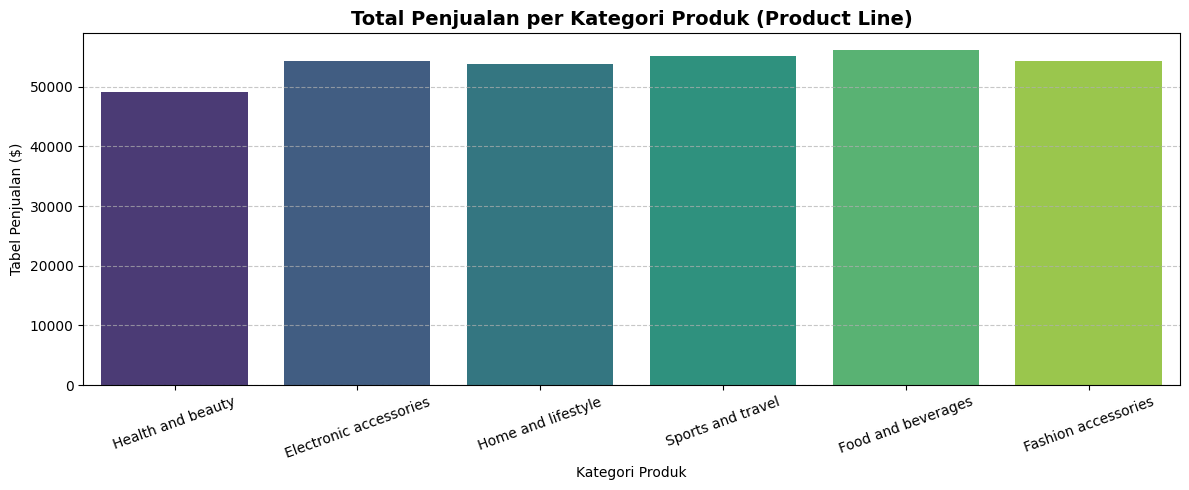

In [ ]:
from matplotlib.typing import LineStyleType
#Visualisasi 1: Distribusi penjualan berdasarkan Product Line
plt.figure(figsize=(12, 5))
sns.barplot(data=df, x='Product line', y='Total', estimator=sum, errorbar= None, palette='viridis')
plt.title('Total Penjualan per Kategori Produk (Product Line)', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Produk')
plt.ylabel('Tabel Penjualan ($)')
plt.xticks(rotation=20)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

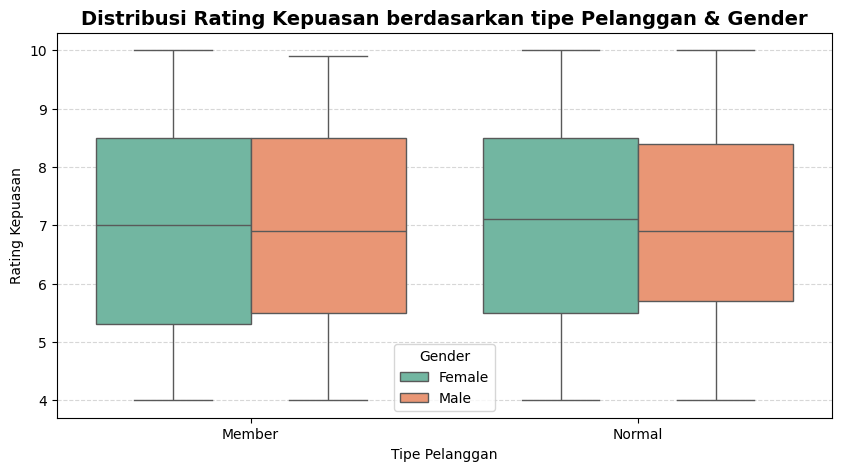

In [ ]:
#Visualisasi 2: Hubungan Customer Type, Gender, dan Rating
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Customer type', y='Customer stratification rating', hue='Gender', palette='Set2')
plt.title('Distribusi Rating Kepuasan berdasarkan tipe Pelanggan & Gender', fontsize=14, fontweight='bold')
plt.ylabel('Rating Kepuasan')
plt.xlabel('Tipe Pelanggan')
plt.legend(title='Gender')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import statsmodels.api as sm
#memastikan kolom Date bertipe datetime dan jadi index
df['Date']=pd.to_datetime(df['Date'])
df_time = df.set_index('Date')

In [ ]:
#agregasikan total penjualan berdasarkan HARIAN ('D')
#jika data terlalu fluktuatif, kita bisa ubah ke MINGGUAN {'W'} nanti
daily_sales = df_time['Total'].resample('D').sum().fillna(0)

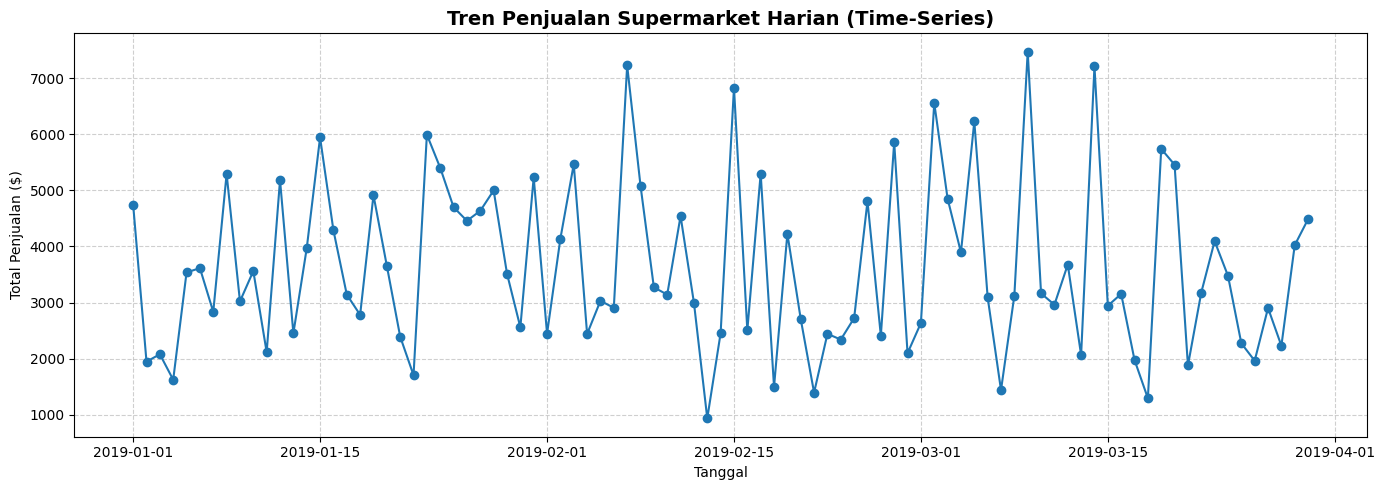

In [ ]:
from matplotlib import colors
#visualisasikan Tren Waktu Asli Penjualan Harian
plt.figure(figsize=(14, 5))
plt.plot(daily_sales, marker='o', color='tab:blue', linestyle='-', linewidth=1.5)
plt.title('Tren Penjualan Supermarket Harian (Time-Series)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
#Uji Stasioneritas (Adf Test) - Syarat wajib sebelum modeling statistik
from statsmodels.tsa.stattools import adfuller
adf_result = adfuller(daily_sales)
print("---Hasil Uji Augmented Dicky-Fuller (ADF)---")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
if adf_result[1] <=0.05:
  print("Kesimpulan: Data bersifat STASIONER (Siap digunakan untuk Modeling).")
else:
  print("Kesimpulan: Data TIDAK STASIONER (Perlu Proses Differencing Dulu).")

---Hasil Uji Augmented Dicky-Fuller (ADF)---
ADF Statistic: -7.6549
p-value: 0.0000
Kesimpulan: Data bersifat STASIONER (Siap digunakan untuk Modeling).


/tmp/ipykernel_1213/1784264023.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(daily_sales)


In [ ]:
# 1. Agregasikan data penjualan menjadi total HARIAN
# Menggunakan kolom 'Date' yang sudah bertipe datetime sebagai basis pengelompokan
daily_sales = df.groupby('Date')['Total'].sum().reset_index()
daily_sales = daily_sales.set_index('Date').asfreq('D', fill_value=0)

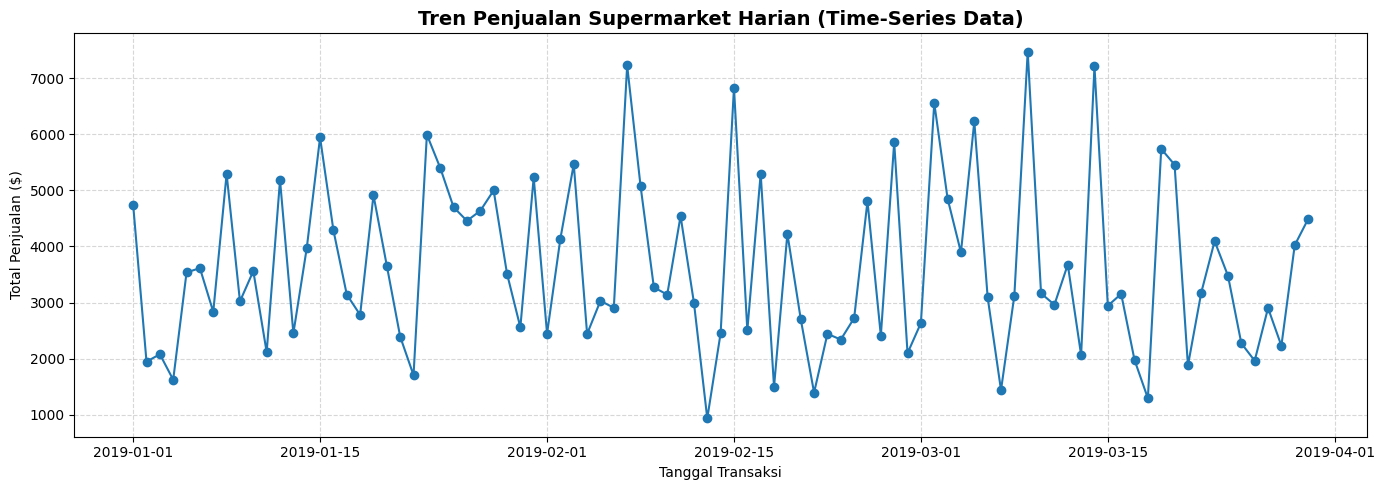

In [ ]:
# 2. Visualisasi Tren Penjualan Harian
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales['Total'], marker='o', color='#1f77b4', linestyle='-', linewidth=1.5)
plt.title('Tren Penjualan Supermarket Harian (Time-Series Data)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal Transaksi')
plt.ylabel('Total Penjualan ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# 3. Uji Stasioneritas dengan Augmented Dickey-Fuller (ADF) Test
print("="*50)
print("PENGUJIAN STASIONERITAS DATA (ADF TEST)")
print("="*50)
adf_test = adfuller(daily_sales['Total'])

print(f"ADF Statistic : {adf_test[0]:.4f}")
print(f"p-value       : {adf_test[1]:.4f}")
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value:.4f}")

if adf_test[1] <= 0.05:
    print("\n[KESIMPULAN]: Data bersifat STASIONER. Kita bisa langsung menggunakan model ARIMA/SARIMAX.")
else:
    print("\n[KESIMPULAN]: Data TIDAK STASIONER. Perlu proses differencing (d) sebelum masuk model ARIMA.")

PENGUJIAN STASIONERITAS DATA (ADF TEST)
ADF Statistic : -7.6549
p-value       : 0.0000
Critical Values:
   1%: -3.5079
   5%: -2.8954
   10%: -2.5848

[KESIMPULAN]: Data bersifat STASIONER. Kita bisa langsung menggunakan model ARIMA/SARIMAX.


/tmp/ipykernel_1213/2049549249.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_test = adfuller(daily_sales['Total'])


In [ ]:
# 1. Pastikan kolom Date bertipe datetime dan lakukan agregasi harian
df['Date'] = pd.to_datetime(df['Date'])
daily_sales = df.groupby('Date')['Total'].sum().reset_index()

In [ ]:
# 2. Set Date sebagai index dan atur frekuensi harian ('D')
daily_sales = daily_sales.set_index('Date').asfreq('D', fill_value=0)

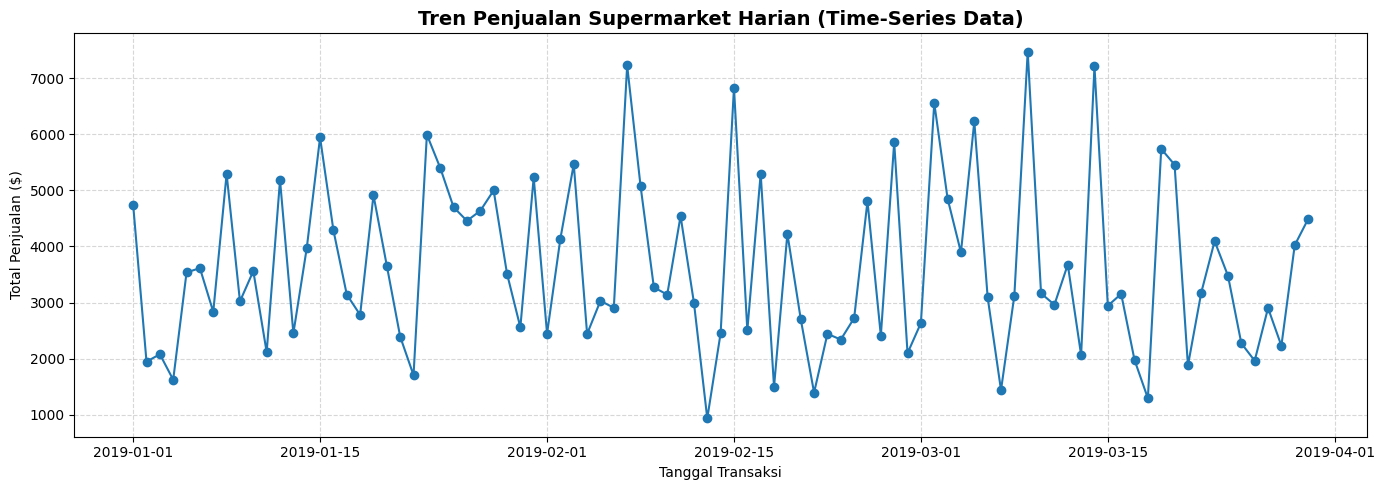

In [ ]:
# 3. Visualisasikan Tren Penjualan Harian
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales['Total'], marker='o', color='#1f77b4', linestyle='-', linewidth=1.5)
plt.title('Tren Penjualan Supermarket Harian (Time-Series Data)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal Transaksi')
plt.ylabel('Total Penjualan ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# 4. Pengujian Stasioneritas dengan Augmented Dickey-Fuller (ADF) Test
print("="*60)
print("PENGUJIAN STASIONERITAS DATA (ADF TEST)")
print("="*60)
adf_test = adfuller(daily_sales['Total'])

print(f"ADF Statistic : {adf_test[0]:.4f}")
print(f"p-value       : {adf_test[1]:.4f}")
print("\nCritical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value:.4f}")

print("-"*60)
if adf_test[1] <= 0.05:
    print("[KESIMPULAN]: Data bersifat STASIONER.")
    print("Artinya, nilai rata-rata dan varians data stabil dari waktu ke waktu.")
    print("Kita bisa langsung menggunakan model ARIMA/SARIMAX tanpa proses differencing tambahan.")
else:
    print("[KESIMPULAN]: Data TIDAK STASIONER.")
    print("Artinya, data memiliki tren naik/turun yang kuat.")
    print("Kita perlu melakukan proses differencing (d=1) sebelum masuk ke model ARIMA.")
print("="*60)

PENGUJIAN STASIONERITAS DATA (ADF TEST)
ADF Statistic : -7.6549
p-value       : 0.0000

Critical Values:
   1%: -3.5079
   5%: -2.8954
   10%: -2.5848
------------------------------------------------------------
[KESIMPULAN]: Data bersifat STASIONER.
Artinya, nilai rata-rata dan varians data stabil dari waktu ke waktu.
Kita bisa langsung menggunakan model ARIMA/SARIMAX tanpa proses differencing tambahan.


/tmp/ipykernel_1213/326912245.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_test = adfuller(daily_sales['Total'])


In [ ]:
from prophet import Prophet

In [ ]:
# 1. Menyiapkan data sesuai format wajib Prophet (Kolom harus bernama 'ds' dan 'y')
df_prophet = daily_sales.reset_index()
df_prophet.columns = ['ds', 'y']

In [ ]:
# 2. Inisialisasi dan fitting model Prophet
# Kita aktifkan evaluasi pola musiman mingguan (weekly_seasonality)
model = Prophet(weekly_seasonality=True, daily_seasonality=False, yearly_seasonality=False)
model.fit(df_prophet)

In [ ]:
# 3. Membuat dataframe masa depan untuk prediksi (contoh: 14 hari ke depan)
future = model.make_future_dataframe(periods=14, freq='D')
forecast = model.predict(future)

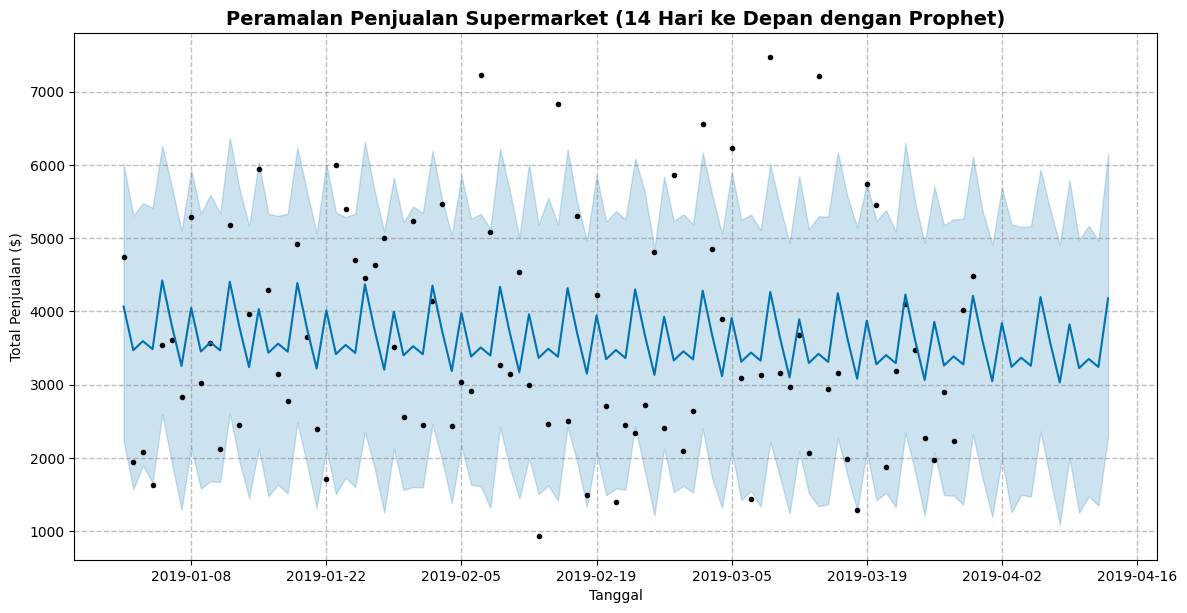

In [ ]:
# 4. Visualisasi Hasil Prediksi Penjualan
fig1 = model.plot(forecast, figsize=(12, 6))
plt.title('Peramalan Penjualan Supermarket (14 Hari ke Depan dengan Prophet)', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

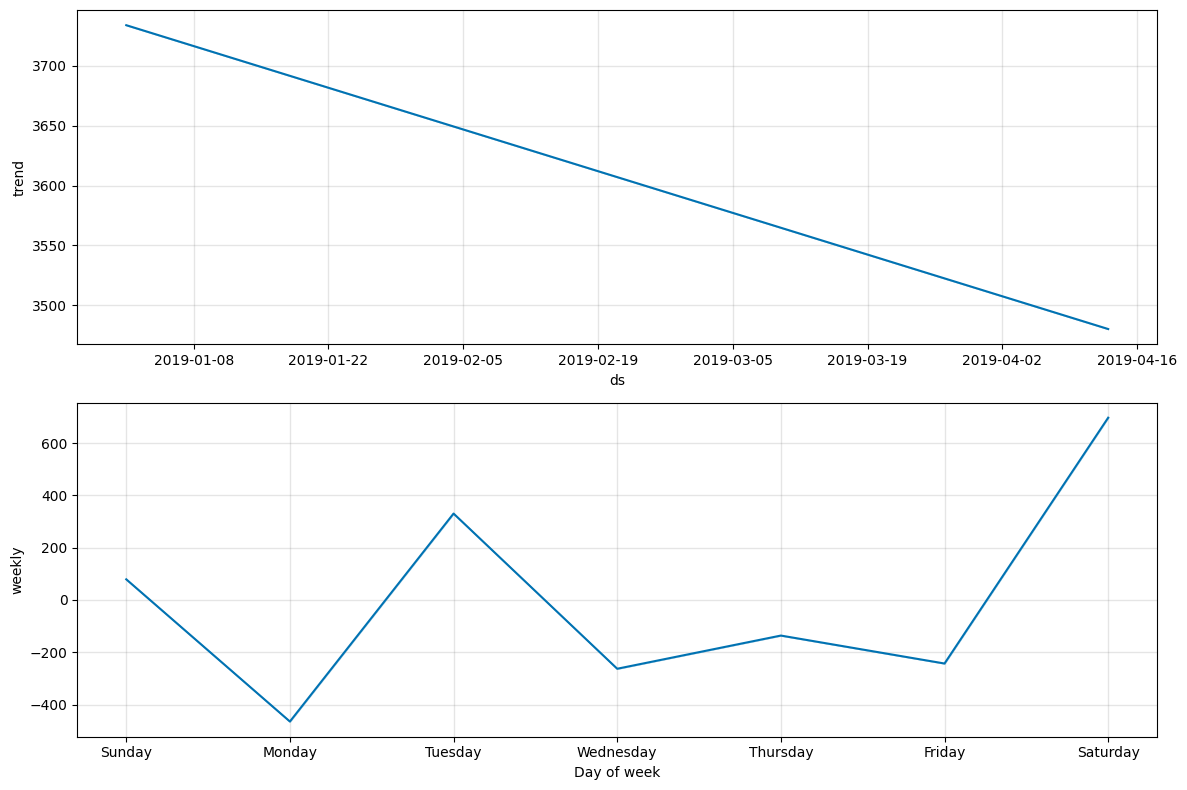

In [ ]:
# 5. Visualisasi Komponen Tren dan Pola Musiman (Mingguan)
fig2 = model.plot_components(forecast, figsize=(12, 8))
plt.show()

In [ ]:
from prophet import Prophet
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

In [ ]:
# 1. Menyiapkan Data & Splitting (80% Train, 20% Test)
# Menggunakan data daily_sales yang sudah stasioner
df_model = daily_sales.copy()
train_size = int(len(df_model) * 0.8)
train, test = df_model.iloc[:train_size], df_model.iloc[train_size:]

print(f"Jumlah Data Training : {len(train)} hari")
print(f"Jumlah Data Testing  : {len(test)} hari\n")

# =========================================================================
# MODEL 1: ARIMA (Menggunakan parameter standar untuk data stasioner p=1, d=0, q=1)
# =========================================================================
arima_model = ARIMA(train['Total'], order=(1, 0, 1))
arima_result = arima_model.fit()
arima_pred = arima_result.forecast(steps=len(test))

Jumlah Data Training : 71 hari
Jumlah Data Testing  : 18 hari



In [ ]:
# =========================================================================
# MODEL 2: PROPHET (Meta)
# =========================================================================
# Format ulang data khusus untuk Prophet
df_train_p = train.reset_index().rename(columns={'Date': 'ds', 'Total': 'y'})
df_test_p = test.reset_index().rename(columns={'Date': 'ds', 'Total': 'y'})

prophet_model = Prophet(weekly_seasonality=True, daily_seasonality=False, yearly_seasonality=False)
prophet_model.fit(df_train_p)

# Prediksi seukuran data testing
future = prophet_model.make_future_dataframe(periods=len(test), freq='D')
forecast = prophet_model.predict(future)
prophet_pred = forecast.iloc[train_size:]['yhat'].values


In [ ]:
# =========================================================================
# EVALUASI & PERBANDINGAN PERFORMA
# =========================================================================
# Evaluasi ARIMA
mae_arima = mean_absolute_error(test['Total'], arima_pred)
mape_arima = mean_absolute_percentage_error(test['Total'], arima_pred) * 100


In [ ]:
# Evaluasi Prophet
mae_prophet = mean_absolute_error(test['Total'], prophet_pred)
mape_prophet = mean_absolute_percentage_error(test['Total'], prophet_pred) * 100

In [ ]:
# Tampilkan Tabel Hasil Evaluasi
metrics_df = pd.DataFrame({
    'Model': ['ARIMA (1,0,1)', 'Meta Prophet'],
    'MAE (Mean Absolute Error)': [f"${mae_arima:.2f}", f"${mae_prophet:.2f}"],
    'MAPE (Persentase Error)': [f"{mape_arima:.2f}%", f"{mape_prophet:.2f}%"]
})
print("="*50)
print("HASIL PERBANDINGAN AKURASI MODEL")
print("="*50)
print(metrics_df.to_string(index=False))
print("="*50)

HASIL PERBANDINGAN AKURASI MODEL
        Model MAE (Mean Absolute Error) MAPE (Persentase Error)
ARIMA (1,0,1)                  $1326.17                  50.61%
 Meta Prophet                  $1331.64                  50.72%


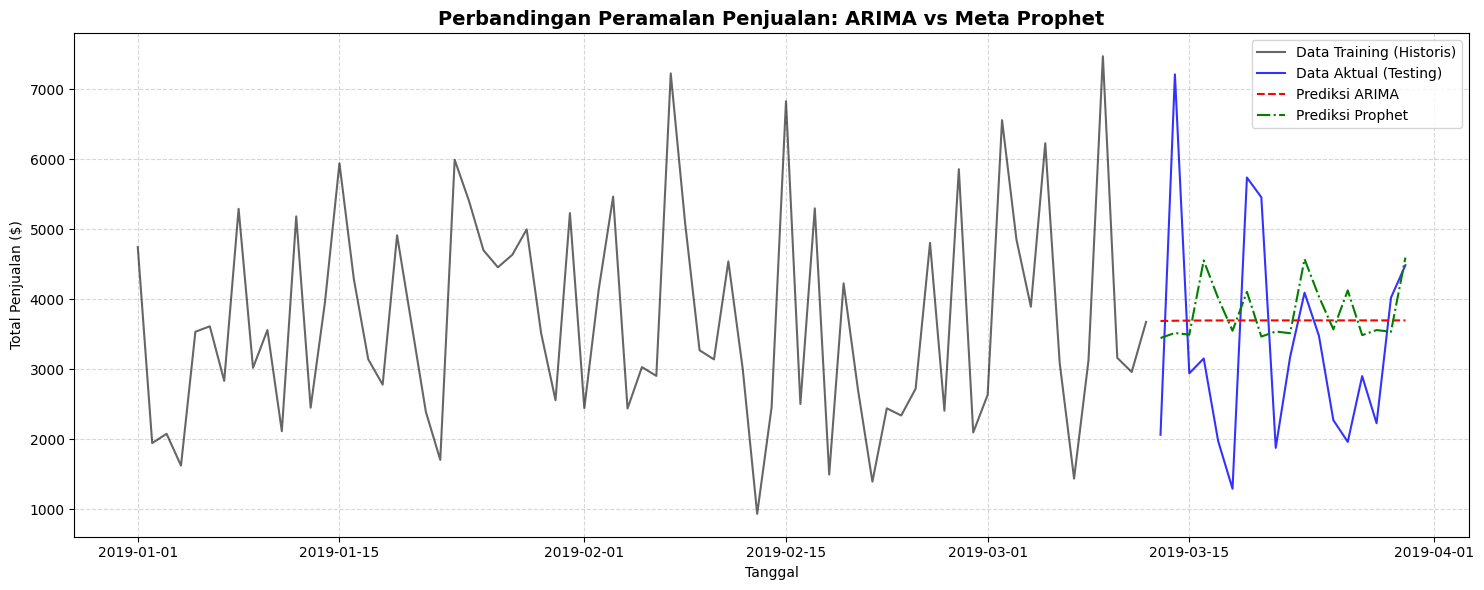

In [ ]:
# =========================================================================
# VISUALISASI PERBANDINGAN HASIL PREDIKSI
# =========================================================================
plt.figure(figsize=(15, 6))
plt.plot(train.index, train['Total'], label='Data Training (Historis)', color='black', alpha=0.6)
plt.plot(test.index, test['Total'], label='Data Aktual (Testing)', color='blue', alpha=0.8)
plt.plot(test.index, arima_pred, label='Prediksi ARIMA', color='red', linestyle='--')
plt.plot(test.index, prophet_pred, label='Prediksi Prophet', color='green', linestyle='-.')

plt.title('Perbandingan Peramalan Penjualan: ARIMA vs Meta Prophet', fontsize=14, fontweight='bold')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()